# TensorForge 2.1.0 — Design, evaluation and findings

**Model:** `tf-phase2-drive-2.1.0` · **Release:** `v2.1.0` · **Product:** Fresh Desk support-ticket routing for RideEat

Fresh Desk reads a customer support ticket (chat, email, or call transcript, in English, Sinhala, Tamil, their Latin-script forms, or a mix) and predicts three things: the **primary category** (11 classes), an optional **secondary category**, and whether the ticket is **urgent**. The support **team** is not predicted; it is derived from the primary category with the fixed routing table in the contract.

This report has three parts:

1. **Design decisions** — what we built and why, including what we rejected.
2. **Evaluation scores** — held-out results on a deterministic, stratified 75/25 split of `train.csv` (3,000 fit / 1,000 untouched test tickets).
3. **Findings** — what the scores show, where the model is weak, and the limits of this evaluation.

All scores come from models fitted on the 75% fold. The deployed artifact was then refit on all 4,800 labelled rows (`train.csv` plus `validation.csv`) and must not be re-scored on those rows. The data are synthetic workshop examples: good scores here do not guarantee quality on real customer messages or on the judges' independent data.

### Setup

Scores are read from `artifacts/evaluation_metrics.json`. Set `RETRAIN = True` to reproduce the split, the held-out scoring, and the final refit with `scripts/train_model.py`. Retraining **overwrites** `artifacts/model.joblib` and the saved metrics.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

RETRAIN = False  # True re-runs the 75/25 evaluation and the final refit (overwrites artifacts/model.joblib)
if RETRAIN:
    from scripts.train_model import run_training
    run_training(
        train_path=ROOT / "datasets/train.csv",
        validation_path=ROOT / "datasets/validation.csv",
        config_path=ROOT / "configs/training.json",
        output_dir=ROOT / "artifacts",
        test_size=0.25,
        random_state=42,
    )

metrics = json.loads((ROOT / "artifacts/evaluation_metrics.json").read_text(encoding="utf-8"))
config = json.loads((ROOT / "configs/training.json").read_text(encoding="utf-8"))
assert metrics["model_version"] == "tf-phase2-drive-2.1.0"
assert metrics["evaluation_split"]["fit_examples"] == 3000
assert metrics["evaluation_split"]["test_examples"] == 1000

pd.set_option("display.max_colwidth", None)
TEAL, LIME, DEEP, GREY = "#0f9f8a", "#9ccc3c", "#133d36", "#c9d6d2"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.grid": True, "grid.alpha": 0.25,
    "axes.prop_cycle": plt.cycler(color=[TEAL, LIME, DEEP, "#5eead4"]),
})
experiments = json.loads((ROOT / "artifacts/training_experiments.json").read_text(encoding="utf-8"))
TARGETS = {"category": "Primary category", "secondary_category": "Secondary category", "is_urgent": "Urgency"}
print(metrics["model_version"])
print(metrics["evaluation_note"])

tf-phase2-drive-2.1.0
Metrics are from the untouched 25% stratified test fold of train.csv. After scoring, the deployment artifact was refit on train.csv plus validation.csv; do not evaluate that final artifact on these same examples.


# Part 1 — Design decisions

| Area | Decision | Why | Rejected or avoided |
| --- | --- | --- | --- |
| Approach | Our own trained classifiers, served locally | The brief discourages LLM wrappers; local models need no network, key, or download at runtime | Calling an LLM or a hosted model API |
| Features | Word 1–2 grams + character 2–6 grams (TF-IDF) | Words capture issue phrases; character fragments survive misspellings, Sinhala/Tamil scripts, and transliteration — no translation step | Translating to English first; ticket IDs and dataset language labels as features |
| Targets | Three separate models, one per output | Each output has different class balance and needs its own threshold | One joint model for all outputs |
| Team | Derived from the primary category via the fixed table | The contract defines the mapping; predicting it separately could contradict the category | A fourth "team" classifier |
| Consistency | Post-prediction rules: secondary ≠ primary; spam is never urgent and has no secondary | Guarantees contract-valid output even when a model disagrees | Trusting raw model outputs |
| Human review | Recommended when primary confidence < 0.5 or the message has ≤ 3 words; urgent tickets go to the support queue | Keeps a person in the loop exactly where the model is least reliable | Fully automatic routing |
| Model selection | Configurations and cutoffs chosen on the supplied development validation set | A first candidate chosen on an internal training split scored poorly on validation and was dropped (see Findings) | Selecting on internal splits of synthetic data |
| Serving | FastAPI; auth → content type → size → JSON → validation, in contract order; sync batches ≤ 100, async jobs ≤ 5,000 | An unauthorised or malformed request never reaches the model; large runs don't block health checks | Unbounded synchronous batches |
| Packaging | One Docker image with UI, model, and dependencies; runs with networking disabled | Matches the evaluation's offline, single-`docker run` requirement | Downloading the model at start-up |


## 1.1 Models and why

All targets share a scikit-learn TF-IDF pipeline. Ticket channel, subject, and message are features; an optional language hint is used when supplied. Text is Unicode NFC-normalized; secondary and urgency preprocessing also normalizes spacing, masks synthetic references, and removes explicitly quoted past correspondence.

- **Primary category — balanced Logistic Regression, `C=100`.** Efficient on sparse word and boundary-aware `char_wb` 2–6-gram features, and returns class probabilities for routing and confidence. Balanced class weights reduce majority-class preference.
- **Secondary category — sigmoid-calibrated Linear SVM, `C=1`, cutoff `0.20`.** A margin classifier suits sparse high-dimensional text; three-fold sigmoid calibration gives probabilities for the optional-label cutoff. The low cutoff reflects that a second issue is optional and must differ from the primary.
- **Urgency — balanced Logistic Regression, `C=40`, cutoff `0.30`.** Probabilities support an explicit operating threshold, set below 0.5 to favour catching urgent tickets; class balancing keeps the rarer urgent class from being ignored.

The frozen configuration from `configs/training.json`:

In [2]:
config_rows = []
for target, values in config["models"].items():
    config_rows.append({
        "target": TARGETS[target],
        "estimator": values["estimator"],
        "C": values["C"],
        "class weight": values["class_weight"],
        "normalize": values["normalize"],
        "char analyzer": values["char_analyzer"],
        "char n-grams": str(values["char_ngram_range"]),
        "decision threshold": values.get("threshold", "argmax"),
    })
display(pd.DataFrame(config_rows).set_index("target"))

,estimator,C,class weight,normalize,char analyzer,char n-grams,decision threshold
target,,,,,,,
Primary category,logistic_regression,100.0,balanced,False,char_wb,"[2, 6]",argmax
Secondary category,calibrated_svm,1.0,None,True,char,"[2, 6]",0.2
Urgency,logistic_regression,40.0,balanced,True,char,"[2, 5]",0.3


# Part 2 — Evaluation scores

## 2.1 Data and split

Only the organisers' synthetic workshop data is used. The split is stratified by primary category with a fixed seed (42), so it is reproducible. `validation.csv` is not used for test scoring; it joins the training data only for the final refit.

,value
method,stratified random split by primary category from train.csv only
test_size,0.25
random_state,42
fit_examples,3000
test_examples,1000
validation_file_used_for_test_scoring,False


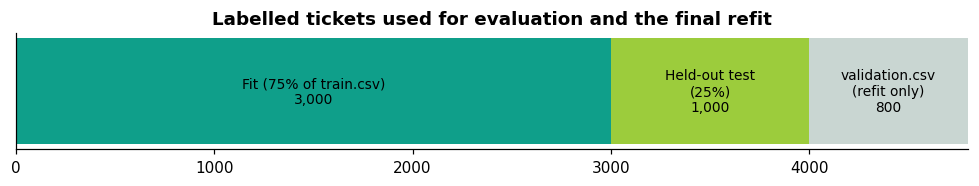

In [3]:
split = metrics["evaluation_split"]
display(pd.Series(split, name="value").to_frame())

fig, ax = plt.subplots(figsize=(9, 1.8))
parts = [("Fit (75% of train.csv)", split["fit_examples"], TEAL),
         ("Held-out test\n(25%)", split["test_examples"], LIME),
         ("validation.csv\n(refit only)", len(pd.read_csv(ROOT / "datasets/validation.csv")), GREY)]
left = 0
for label, n, color in parts:
    ax.barh(0, n, left=left, color=color)
    ax.text(left + n / 2, 0, f"{label}\n{n:,}", ha="center", va="center", fontsize=9)
    left += n
ax.set(xlim=(0, left), yticks=[], title="Labelled tickets used for evaluation and the final refit")
ax.grid(False)
fig.tight_layout()
plt.show()

## 2.2 Overall held-out scores

Accuracy is the fraction of correct predictions. Macro-F1 averages per-class F1 with every class weighted equally, so rare labels count as much as common ones. Secondary labels include a `__none__` outcome. Scores include the consistency and precedence rules.

,accuracy (%),macro-F1 (%)
prediction target,,
Primary category,99.0,98.92
Secondary category,99.8,98.84
Urgency,99.9,99.71


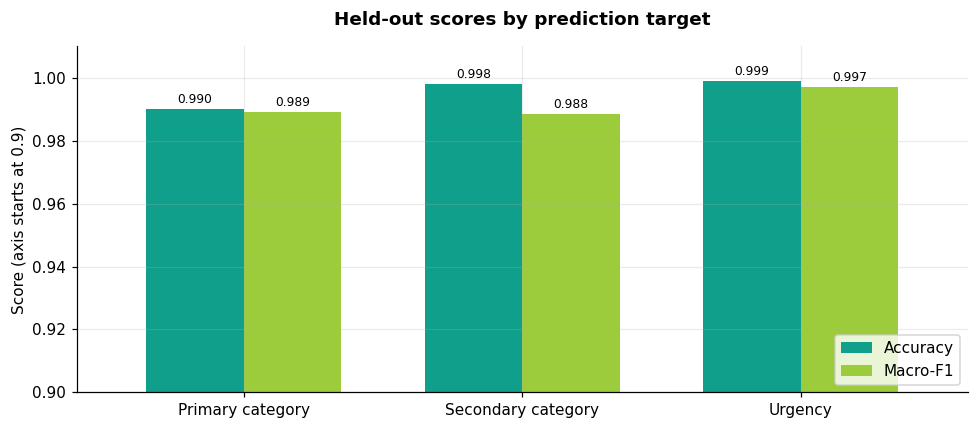

In [4]:
overall = pd.DataFrame(metrics["validation"]).T.rename(index=TARGETS)
overall.index.name = "prediction target"
display((100 * overall).round(2).rename(columns={"accuracy": "accuracy (%)", "macro_f1": "macro-F1 (%)"}))

ax = overall.rename(columns={"accuracy": "Accuracy", "macro_f1": "Macro-F1"}).plot.bar(
    figsize=(9, 4), ylim=(0.9, 1.01), rot=0, width=0.7)
ax.set_title("Held-out scores by prediction target", pad=14)
ax.legend(loc="lower right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylabel("Score (axis starts at 0.9)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 2.3 Every class: precision, recall, F1, and support

Support is the number of test tickets for the class. Sparse secondary labels have low support, so their scores are less certain.

Primary category


,precision,recall,f1-score,support
account_promo,0.9889,0.9889,0.9889,90
app_technical,0.9756,1.0000,0.9877,80
delivery_delay,0.9740,1.0000,0.9868,150
food_quality,1.0000,0.9857,0.9928,70
general_inquiry,0.9804,1.0000,0.9901,50
lost_item,0.9796,0.9600,0.9697,50
order_missing_wrong,1.0000,0.9833,0.9916,120
payment_refund,1.0000,0.9944,0.9972,180
ride_trip_issue,0.9928,0.9857,0.9892,140
safety_conduct,1.0000,0.9750,0.9873,40


Secondary category


,precision,recall,f1-score,support
__none__,1.0000,0.9989,0.9994,903
app_technical,1.0000,1.0000,1.0000,16
delivery_delay,1.0000,0.9286,0.9630,14
order_missing_wrong,1.0000,1.0000,1.0000,8
payment_refund,0.9375,1.0000,0.9677,30
ride_trip_issue,1.0000,1.0000,1.0000,29
macro avg,0.9896,0.9879,0.9884,1000
weighted avg,0.9981,0.9980,0.9980,1000


Urgency


,precision,recall,f1-score,support
false,0.9989,1.0000,0.9994,905
true,1.0000,0.9895,0.9947,95
macro avg,0.9994,0.9947,0.9971,1000
weighted avg,0.9990,0.9990,0.9990,1000


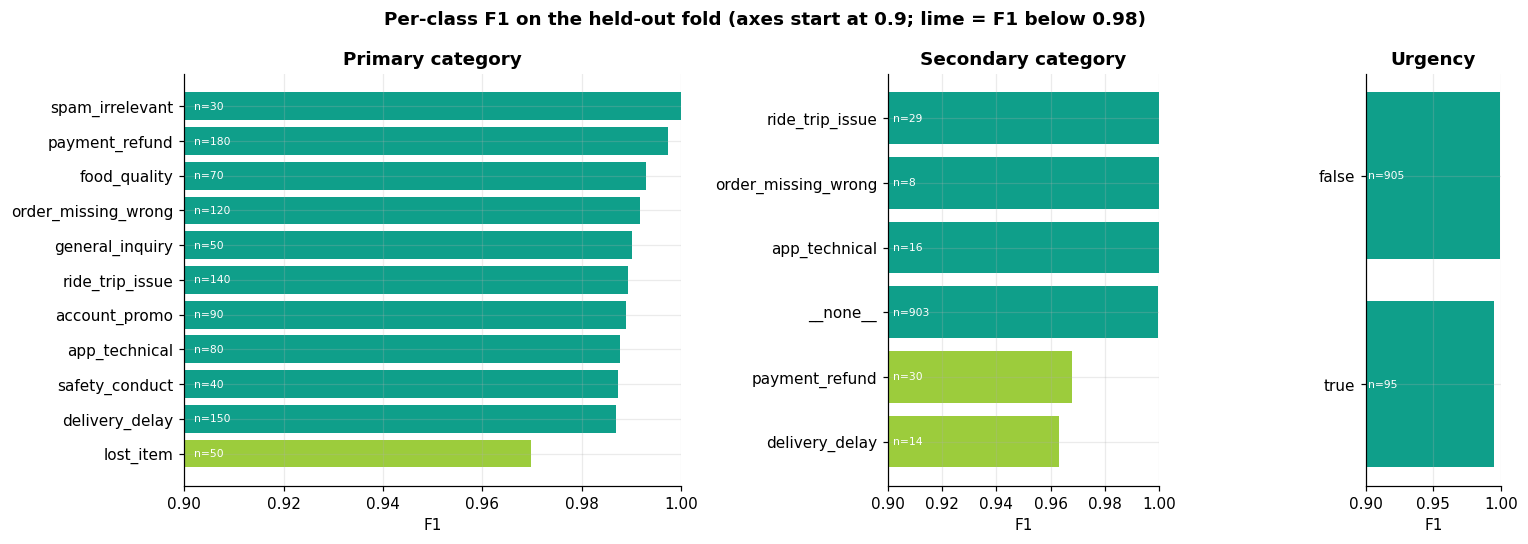

In [5]:
reports = {}
for target, report in metrics["classification_reports"].items():
    rows = {label: scores for label, scores in report.items() if isinstance(scores, dict)}
    table = pd.DataFrame(rows).T[["precision", "recall", "f1-score", "support"]]
    table["support"] = table["support"].astype(int)
    reports[target] = table
    print(TARGETS[target])
    display(table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw={"width_ratios": [11, 6, 3]})
for ax, (target, table) in zip(axes, reports.items()):
    classes = table.drop(index=["macro avg", "weighted avg"], errors="ignore").sort_values("f1-score")
    colors = [LIME if score < 0.98 else TEAL for score in classes["f1-score"]]
    ax.barh(classes.index, classes["f1-score"], color=colors)
    ax.set(xlim=(0.9, 1.0), title=TARGETS[target], xlabel="F1")
    for y, (score, n) in enumerate(zip(classes["f1-score"], classes["support"])):
        ax.text(0.902, y, f"n={n}", va="center", fontsize=7, color="white")
fig.suptitle("Per-class F1 on the held-out fold (axes start at 0.9; lime = F1 below 0.98)", fontweight="bold")
fig.tight_layout()
plt.show()

## 2.4 Confusion matrices

Rows are actual labels; columns are predicted labels, after the precedence and consistency rules.

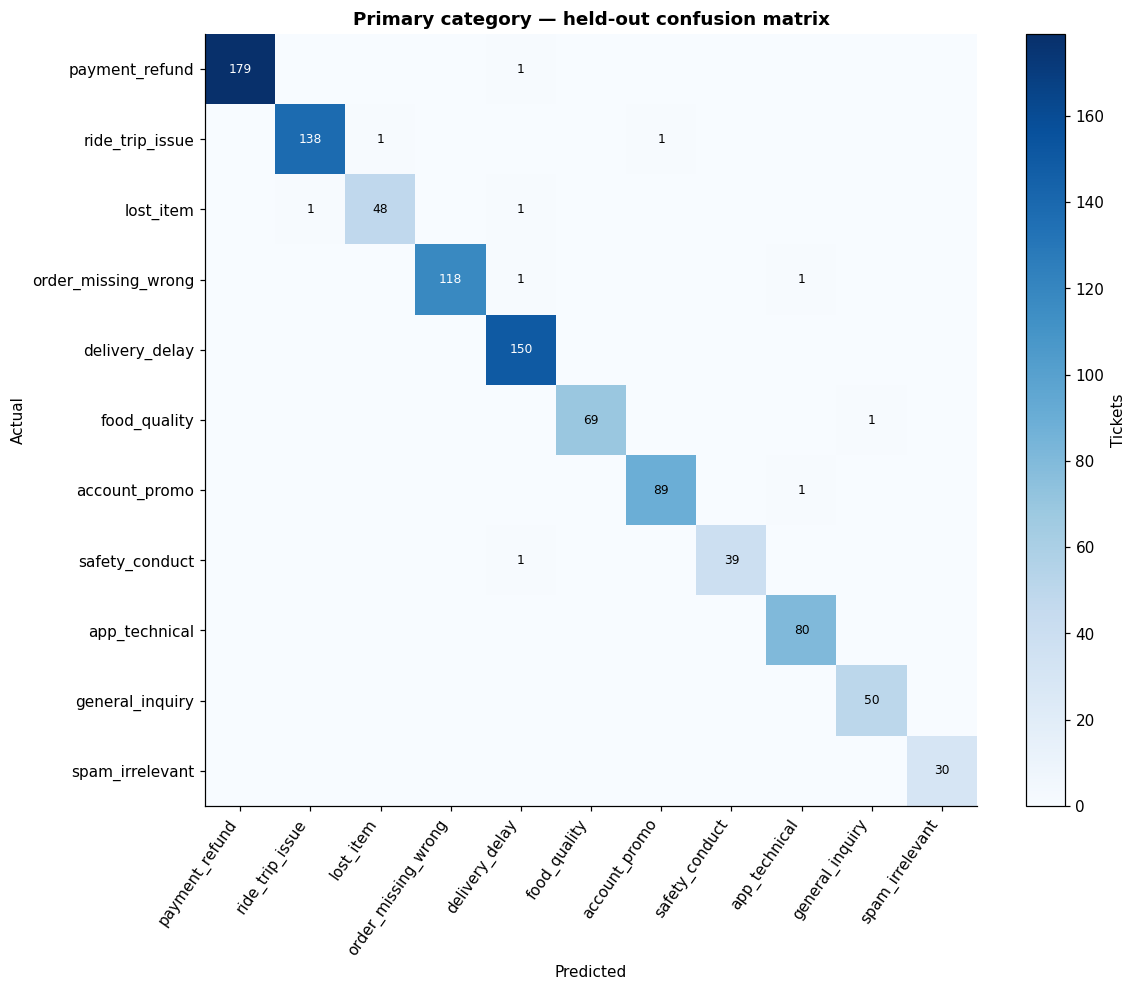

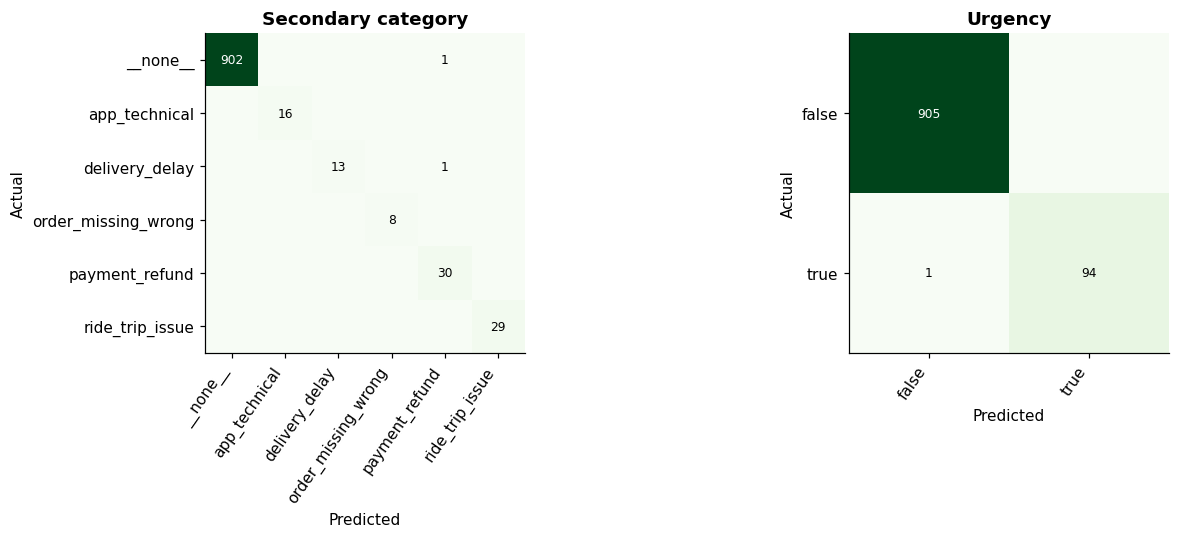

In [6]:
category_matrix = metrics["category_confusion_matrix"]
labels = category_matrix["labels"]
matrix = np.asarray(category_matrix["rows_actual_columns_predicted"])

def draw_matrix(ax, cm, class_labels, title, cmap):
    image = ax.imshow(cm, cmap=cmap)
    ax.set(title=title, xlabel="Predicted", ylabel="Actual",
           xticks=range(len(class_labels)), yticks=range(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=55, ha="right")
    ax.set_yticklabels(class_labels)
    ax.grid(False)
    for row in range(len(class_labels)):
        for column in range(len(class_labels)):
            if cm[row, column]:
                dark = cm[row, column] > cm.max() / 2
                ax.text(column, row, str(cm[row, column]), ha="center", va="center", fontsize=8,
                        color="white" if dark else "black")
    return image

fig, ax = plt.subplots(figsize=(11, 9))
fig.colorbar(draw_matrix(ax, matrix, labels, "Primary category — held-out confusion matrix", "Blues"), ax=ax, label="Tickets")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [3, 1.3]})
for ax, target in zip(axes, ["secondary_category", "is_urgent"]):
    class_labels = [name for name in reports[target].index if name not in ("macro avg", "weighted avg")]
    cm = np.asarray(metrics["confusion_matrices"][target]["rows_actual_columns_predicted"])
    draw_matrix(ax, cm, class_labels, TARGETS[target], "Greens")
fig.tight_layout()
plt.show()

Most frequent primary-category mistakes:

In [7]:
display(pd.DataFrame(metrics["top_category_confusions"]))

,actual,predicted,count
0,order_missing_wrong,delivery_delay,1
1,ride_trip_issue,account_promo,1
2,ride_trip_issue,lost_item,1
3,lost_item,ride_trip_issue,1
4,safety_conduct,delivery_delay,1
5,order_missing_wrong,app_technical,1
6,lost_item,delivery_delay,1
7,account_promo,app_technical,1
8,food_quality,general_inquiry,1
9,payment_refund,delivery_delay,1


## 2.5 Performance by language

Primary-category scores grouped by the dataset language tag. Group sizes differ greatly; the `mixed` and `tanglish` groups have only about twenty test tickets each.

,count,accuracy,macro_f1
en,356,0.9831,0.9825
mixed,23,1.0000,1.0000
si,198,1.0000,1.0000
singlish,255,0.9961,0.9978
ta,146,1.0000,1.0000
tanglish,22,0.8636,0.7778


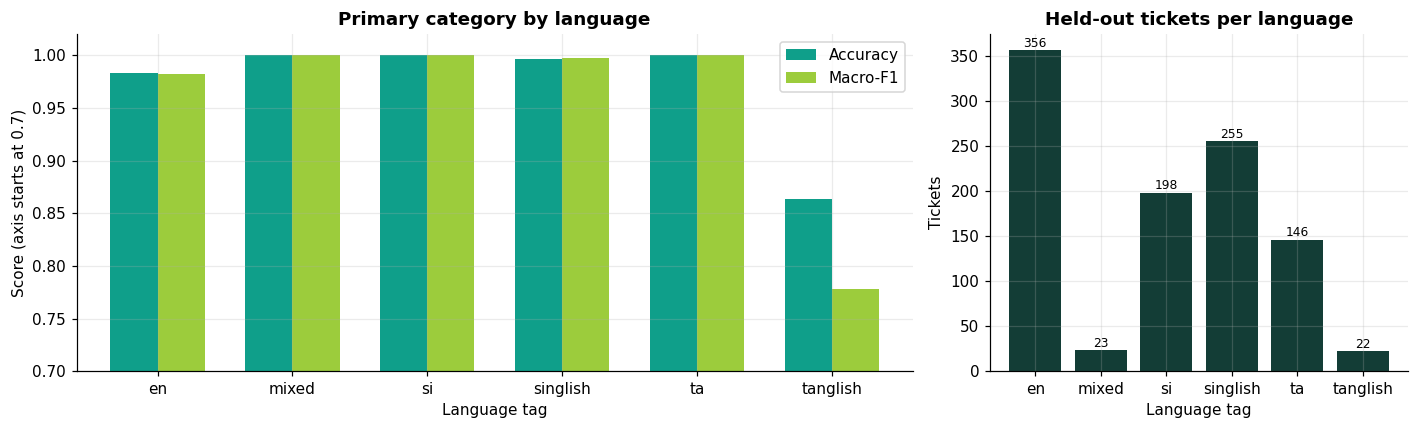

In [8]:
language_scores = pd.DataFrame(metrics["category_by_language"]).T.sort_index()
language_scores["count"] = language_scores["count"].astype(int)
display(language_scores)

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})
language_scores[["accuracy", "macro_f1"]].rename(columns={"accuracy": "Accuracy", "macro_f1": "Macro-F1"}).plot.bar(
    ax=left, ylim=(0.7, 1.02), rot=0, width=0.7, title="Primary category by language")
left.set(ylabel="Score (axis starts at 0.7)", xlabel="Language tag")
right.bar(language_scores.index, language_scores["count"], color=DEEP)
right.set(title="Held-out tickets per language", xlabel="Language tag", ylabel="Tickets")
for x, n in enumerate(language_scores["count"]):
    right.text(x, n + 4, str(n), ha="center", fontsize=8)
fig.tight_layout()
plt.show()

## 2.6 Delivery-delay vs. lost-property routing

A delayed, not-yet-arrived delivery is `delivery_delay`; belongings left during a ride are `lost_item`. The first table isolates these two categories from the held-out confusion matrix. The live predictions are a smoke check of the deployed full-data artifact, not part of the held-out score.

In [9]:
lost_index, delay_index = labels.index("lost_item"), labels.index("delivery_delay")
display(pd.DataFrame(
    [[matrix[lost_index, lost_index], matrix[lost_index, delay_index]],
     [matrix[delay_index, lost_index], matrix[delay_index, delay_index]]],
    index=["actual lost_item", "actual delivery_delay"],
    columns=["predicted lost_item", "predicted delivery_delay"],
))

from app.model import TicketModel
model = TicketModel.load(ROOT / "artifacts/model.joblib")
smoke_tickets = [
    {"channel": "chat", "text": "My food order is delayed and still has not arrived."},
    {"channel": "chat", "text": "I left my phone in the car after my ride."},
]
smoke_predictions = model.predict_many(smoke_tickets)
display(pd.DataFrame([
    {"message": ticket["text"], "category": prediction["category"], "team": prediction["team"],
     "confidence": round(prediction["confidence"], 4)}
    for ticket, prediction in zip(smoke_tickets, smoke_predictions)
]))
assert smoke_predictions[0]["category"] == "delivery_delay"
assert smoke_predictions[1]["category"] == "lost_item"

,predicted lost_item,predicted delivery_delay
actual lost_item,48,1
actual delivery_delay,0,150


,message,category,team,confidence
0,My food order is delayed and still has not arrived.,delivery_delay,Delivery Operations,0.9977
1,I left my phone in the car after my ride.,lost_item,Lost & Found,0.9998


# Part 3 — Findings

The findings below are computed from the saved metrics, so they always match the scores in Part 2.

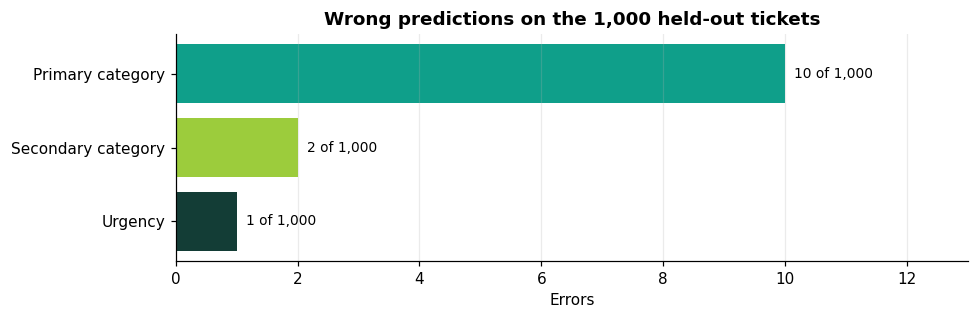

In [10]:
def errors(target):
    cm = np.asarray(metrics["confusion_matrices"][target]["rows_actual_columns_predicted"])
    return int(cm.sum() - np.trace(cm)), int(cm.sum())

err = {TARGETS[t]: errors(t) for t in TARGETS}
fig, ax = plt.subplots(figsize=(9, 3))
names = list(err)
counts = [err[n][0] for n in names]
ax.barh(names, counts, color=[TEAL, LIME, DEEP])
for y, (n, total) in enumerate(err.values()):
    ax.text(n + 0.15, y, f"{n} of {total:,}", va="center", fontsize=9)
ax.set(title="Wrong predictions on the 1,000 held-out tickets", xlabel="Errors", xlim=(0, max(counts) + 3))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

In [11]:
from IPython.display import Markdown

v = metrics["validation"]
cat = reports["category"].drop(index=["macro avg", "weighted avg"])
sec = reports["secondary_category"].drop(index=["macro avg", "weighted avg", "__none__"])
weakest = cat["f1-score"].idxmin()
urgent_cm = np.asarray(metrics["confusion_matrices"]["is_urgent"]["rows_actual_columns_predicted"])
missed_urgent, false_alarms = int(urgent_cm[1, 0]), int(urgent_cm[0, 1])
n_urgent = int(urgent_cm[1].sum())
lang = language_scores.sort_values("accuracy")
low_lang, high_others = lang.index[0], lang.iloc[1:]["accuracy"].min()
top = pd.DataFrame(metrics["top_category_confusions"])
first_candidate = experiments["initial_final_validation"]["category"]["accuracy"]
baseline = experiments["previous_baseline"]["category"]["accuracy"]

Markdown(f"""
### What works

1. **All three outputs score highly on the held-out fold.** Macro-F1 is {100 * v['category']['macro_f1']:.2f}% for the primary category, {100 * v['secondary_category']['macro_f1']:.2f}% for the secondary category, and {100 * v['is_urgent']['macro_f1']:.2f}% for urgency. In total there are {sum(counts)} wrong predictions across {3 * err['Primary category'][1]:,} predictions.
2. **One small model reads every language style.** Character n-grams let a single model handle Sinhala and Tamil scripts, English, and their Latin-script forms without a translation step. Primary accuracy is at least {100 * high_others:.1f}% in every language group except `{low_lang}`.
3. **Urgency is almost error-free.** Of {n_urgent} urgent tickets, {n_urgent - missed_urgent} were flagged and {missed_urgent} was missed, with {false_alarms} false alarms on the {int(urgent_cm[0].sum())} non-urgent tickets. The 0.30 cutoff deliberately favours catching urgent tickets over avoiding false alarms.
4. **Mistakes are scattered, not systematic.** No pair of primary categories is confused more than {int(top['count'].max())} time on the test fold. On the delivery-delay versus lost-property boundary we targeted, all {int(matrix[delay_index].sum())} `delivery_delay` tickets were correct, and {int(matrix[lost_index, delay_index])} of {int(matrix[lost_index].sum())} `lost_item` tickets was predicted as `delivery_delay`.

### Where it is weakest

5. **`{weakest}` is the weakest primary class**, with F1 {cat.loc[weakest, 'f1-score']:.3f} (recall {cat.loc[weakest, 'recall']:.2f}, {int(cat.loc[weakest, 'support'])} test tickets).
6. **Rare secondary labels are less certain.** The lowest secondary F1 is `{sec['f1-score'].idxmin()}` at {sec['f1-score'].min():.3f}, from only {int(sec.loc[sec['f1-score'].idxmin(), 'support'])} test tickets; secondary classes have between {int(sec['support'].min())} and {int(sec['support'].max())} examples each.
7. **`{low_lang}` is the weakest language group**: {100 * lang.loc[low_lang, 'accuracy']:.1f}% accuracy and {100 * lang.loc[low_lang, 'macro_f1']:.1f}% macro-F1, but on only {int(lang.loc[low_lang, 'count'])} tickets, so the estimate is uncertain.

### What we learned about evaluation

8. **Internal splits of synthetic data can mislead model selection.** A first candidate chosen on an internal training split scored only {100 * first_candidate:.2f}% primary accuracy on the supplied validation set (an earlier baseline scored {100 * baseline:.2f}%), so it was rejected. The current configuration and cutoffs were then chosen using the supplied development validation set, and the reported scores come from a 25% fold of `train.csv` that the evaluated models were not fitted on.
9. **Very high scores call for caution, not celebration.** Near-perfect results on synthetic data can reflect repeated templates. The judges' unseen holdout and real customer messages are the true test.

### Limitations

- The data are synthetic and language subgroups are uneven; the `mixed` and `tanglish` groups are too small for firm conclusions.
- Sinhala and Tamil text has not been reviewed by native speakers.
- Confidence is the model probability for the returned primary label; it is not independently calibrated.
- Human review stays essential for short, ambiguous, or low-confidence tickets.
""")


### What works

1. **All three outputs score highly on the held-out fold.** Macro-F1 is 98.92% for the primary category, 98.84% for the secondary category, and 99.71% for urgency. In total there are 13 wrong predictions across 3,000 predictions.
2. **One small model reads every language style.** Character n-grams let a single model handle Sinhala and Tamil scripts, English, and their Latin-script forms without a translation step. Primary accuracy is at least 98.3% in every language group except `tanglish`.
3. **Urgency is almost error-free.** Of 95 urgent tickets, 94 were flagged and 1 was missed, with 0 false alarms on the 905 non-urgent tickets. The 0.30 cutoff deliberately favours catching urgent tickets over avoiding false alarms.
4. **Mistakes are scattered, not systematic.** No pair of primary categories is confused more than 1 time on the test fold. On the delivery-delay versus lost-property boundary we targeted, all 150 `delivery_delay` tickets were correct, and 1 of 50 `lost_item` tickets was predicted as `delivery_delay`.

### Where it is weakest

5. **`lost_item` is the weakest primary class**, with F1 0.970 (recall 0.96, 50 test tickets).
6. **Rare secondary labels are less certain.** The lowest secondary F1 is `delivery_delay` at 0.963, from only 14 test tickets; secondary classes have between 8 and 30 examples each.
7. **`tanglish` is the weakest language group**: 86.4% accuracy and 77.8% macro-F1, but on only 22 tickets, so the estimate is uncertain.

### What we learned about evaluation

8. **Internal splits of synthetic data can mislead model selection.** A first candidate chosen on an internal training split scored only 60.88% primary accuracy on the supplied validation set (an earlier baseline scored 62.88%), so it was rejected. The current configuration and cutoffs were then chosen using the supplied development validation set, and the reported scores come from a 25% fold of `train.csv` that the evaluated models were not fitted on.
9. **Very high scores call for caution, not celebration.** Near-perfect results on synthetic data can reflect repeated templates. The judges' unseen holdout and real customer messages are the true test.

### Limitations

- The data are synthetic and language subgroups are uneven; the `mixed` and `tanglish` groups are too small for firm conclusions.
- Sinhala and Tamil text has not been reviewed by native speakers.
- Confidence is the model probability for the returned primary label; it is not independently calibrated.
- Human review stays essential for short, ambiguous, or low-confidence tickets.


### Release record

- **Release version:** `v2.1.0`; **model version:** `tf-phase2-drive-2.1.0`.
- **Training:** the deployed artifact is trained on 4,800 labelled rows; configurations and thresholds are frozen in `configs/training.json`.
- **Evaluation:** 3,000 / 1,000 stratified fit/test split from `train.csv`, seed 42; `validation.csv` excluded from test scoring.
- **Artifacts:** `artifacts/model.joblib`, `artifacts/evaluation_metrics.json`, `artifacts/evaluation_breakdown.json`, `artifacts/training_experiments.json`.
- **Reproduction:** run `python scripts/train_model.py`, or set `RETRAIN = True` in the setup cell, then run all cells.